<a href="https://colab.research.google.com/github/claragarciaperez/Open_Quantum_Systems_RI/blob/main/qiskit_flipnoise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install qiskit[visualization]
!pip install qiskit-aer
!pip install qiskit-ibm-runtime
!pip install pylatexenc


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import transpile, QuantumCircuit
from qiskit_aer import AerSimulator
import qiskit.quantum_info as qi
from qiskit.visualization import plot_histogram
from qiskit_ibm_runtime import QiskitRuntimeService
from google.colab import drive
from qiskit_aer.noise import (
    NoiseModel,
    QuantumError,
    ReadoutError,
    depolarizing_error,
    pauli_error,
    thermal_relaxation_error,
)
drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Parametes

In [ ]:
Gamma = 0.25
delta_t = 0.5
g = np.sqrt(Gamma/delta_t) # gamma = g^2dt
omega = 1
N = int(30/delta_t)
nshots = 1024


# Load results from Linblad equation

In [ ]:
file_path = (
    '/content/drive/MyDrive/'
    'cont_solution_dt_0.5_g_0.71_omegas_1.txt'
)

data_cont = np.loadtxt(file_path, comments='#')

t_cont = data_cont[:, 0]
sx_cont = data_cont[:, 1]
sy_cont = data_cont[:, 2]
sz_cont = data_cont[:, 3]

# Create Noise model

In [ ]:
p_reset = 0
p_meas = 0.3
p_gate1 = 0

# QuantumError objects
error_reset = pauli_error([("X", p_reset), ("I", 1 - p_reset)])
error_meas = pauli_error([("X", p_meas), ("I", 1 - p_meas)])
error_gate1 = pauli_error([("X", p_gate1), ("I", 1 - p_gate1)])
error_gate2 = error_gate1.tensor(error_gate1)

noise_bit_flip = NoiseModel()
noise_bit_flip.add_all_qubit_quantum_error(error_reset, "reset")
noise_bit_flip.add_all_qubit_quantum_error(error_meas, "measure")
noise_bit_flip.add_all_qubit_quantum_error(error_gate1, ["u1", "u2", "u3"])
noise_bit_flip.add_all_qubit_quantum_error(error_gate2, ["cx"])

In [ ]:
simualtor_aer = AerSimulator()
simulator_aer_noise = AerSimulator(noise_model=noise_bit_flip)


# Refresh Ancilla

### Noise - flip

In [ ]:
def sz_2_circuit(simulator_aer_noise):
  sz_2_noiseflip1 = []
  for niter in range(0,N+1):
      qc = QuantumCircuit(2,1)
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      for i in range(0,niter):
          qc.rxx(g*delta_t,0,1)
          qc.ryy(g*delta_t,0,1)
          qc.rz(-omega*delta_t,0)
          qc.reset(1)
      qc.measure(0,0)
      transpiled_qc = transpile(
      qc,
      backend=simulator_aer_noise,
      optimization_level=3
  )
      job = simulator_aer_noise.run(transpiled_qc,shots = nshots)
      results = job.result().get_counts()
      valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
      sz_2_noiseflip1.append(-valor)
  return sz_2_noiseflip1

In [ ]:
def sx_2_circuit(simulator_aer_noise):
  sx_2_noiseflip1 = []
  for niter in range(0,N+1):
      qc = QuantumCircuit(2,1)
      qc.qubits
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      for i in range(0,niter):
          qc.rxx(g*delta_t,0,1)
          qc.ryy(g*delta_t,0,1)
          qc.rz(-omega*delta_t,0)
          qc.reset(1)
      qc.h(0)
      qc.measure(0,0)

      transpiled_qc = transpile(
      qc,
      backend=simulator_aer_noise,
      optimization_level=3
  )
      job = simulator_aer_noise.run(transpiled_qc,shots = nshots)


      results = job.result().get_counts()
      valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
      sx_2_noiseflip1.append(valor)
  return sx_2_noiseflip1

In [ ]:
def sy_2_circuit(simulator_aer_noise):
  sy_2_noiseflip1 = []
  for niter in range(0,N+1):
      qc = QuantumCircuit(2,1)
      qc.qubits
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      for i in range(0,niter):
          qc.rxx(g*delta_t,0,1)
          qc.ryy(g*delta_t,0,1)
          qc.rz(-omega*delta_t,0)
          qc.reset(1)
      qc.sdg(0)
      qc.h(0)
      qc.measure(0,0)

      transpiled_qc = transpile(
      qc,
      backend=simulator_aer_noise,
      optimization_level=3
  )
      job = simulator_aer_noise.run(transpiled_qc,shots = nshots)

      results = job.result().get_counts()
      valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
      sy_2_noiseflip1.append(-valor)
  return sy_2_noiseflip1

## Plot and save data

### Set of p_reset,p_meas,p_gate1

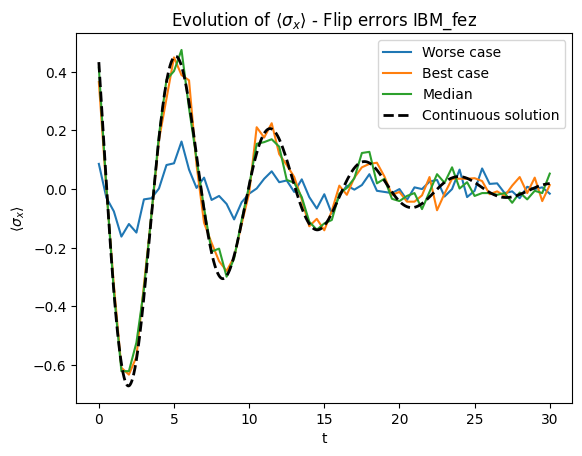

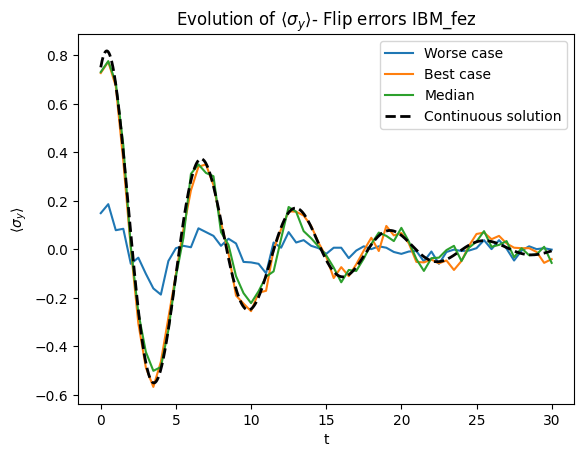

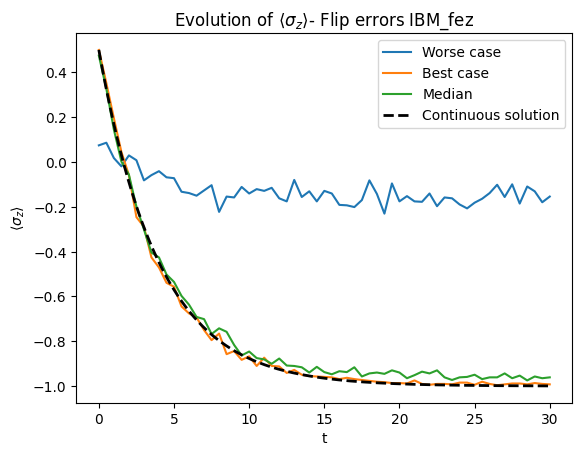

In [ ]:
time = np.arange(N+1) * delta_t

fig_x, ax_x = plt.subplots()
fig_y, ax_y = plt.subplots()
fig_z, ax_z = plt.subplots()

p_reset = 0.03
p_meas = 0.3
p_gate1 = 0.005

for p_reset,p_meas,p_gate1 in [[0.033,0.3955,0.00496],[0.0002,0.002441,0.0000978],[0.002042,0.011,0.0003141]]:

  # QuantumError objects
  error_reset = pauli_error([("X", p_reset), ("I", 1 - p_reset)])
  error_meas = pauli_error([("X", p_meas), ("I", 1 - p_meas)])
  error_gate1 = pauli_error([("X", p_gate1), ("I", 1 - p_gate1)])
  error_gate2 = error_gate1.tensor(error_gate1)

  noise_bit_flip = NoiseModel()
  noise_bit_flip.add_all_qubit_quantum_error(error_reset, "reset")
  noise_bit_flip.add_all_qubit_quantum_error(error_meas, "measure")
  noise_bit_flip.add_all_qubit_quantum_error(error_gate1, ["sdg", "ry", "rz","h"])
  noise_bit_flip.add_all_qubit_quantum_error(error_gate2, ["rxx","ryy"])
  simualtor_aer = AerSimulator()
  simulator_aer_noise = AerSimulator(noise_model=noise_bit_flip)

  sx_2 = sx_2_circuit(simulator_aer_noise)
  sy_2 = sy_2_circuit(simulator_aer_noise)
  sz_2= sz_2_circuit(simulator_aer_noise)

  datos = np.column_stack((time, sx_2, sy_2, sz_2))

  if p_reset == 0.033 and p_meas == 0.3955 and p_gate1 == 0.00496:
    np.savetxt(
      f"/content/drive/MyDrive/qiskit_noiseflipbit_sxsysz_ns1024_fezworsecase.txt",
      datos,
      header="t sx sy sz",
      fmt="%.10f"
    )

    ax_x.plot(time, sx_2, label=rf'Worse case')
    ax_y.plot(time, sy_2, label=rf'Worse case')
    ax_z.plot(time, sz_2, label=rf'Worse case')

  if p_reset == 0.0002 and p_meas == 0.002441 and p_gate1 == 0.0000978:
    np.savetxt(
      f"/content/drive/MyDrive/qiskit_noiseflipbit_sxsysz_ns1024_fezbestcase.txt",
      datos,
      header="t sx sy sz",
      fmt="%.10f"
    )

    ax_x.plot(time, sx_2, label=rf'Best case')
    ax_y.plot(time, sy_2, label=rf'Best case')
    ax_z.plot(time, sz_2, label=rf'Best case')

  if p_reset == 0.002042 and p_meas == 0.011 and p_gate1 == 0.0003141:
    np.savetxt(
      f"/content/drive/MyDrive/qiskit_noiseflipbit_sxsysz_ns1024_fezmedian.txt",
      datos,
      header="t sx sy sz",
      fmt="%.10f"
    )

    ax_x.plot(time, sx_2, label=rf'Median')
    ax_y.plot(time, sy_2, label=rf'Median')
    ax_z.plot(time, sz_2, label=rf'Median')

ax_x.plot(
    t_cont, sx_cont,
    color='black', linestyle='--', linewidth=2,
    label='Continuous solution'
)

ax_y.plot(
    t_cont, sy_cont,
    color='black', linestyle='--', linewidth=2,
    label='Continuous solution'
)

ax_z.plot(
    t_cont, sz_cont,
    color='black', linestyle='--', linewidth=2,
    label='Continuous solution'
)
# Configurar figura de X
ax_x.set_xlabel('t')
ax_x.set_ylabel(r'$\langle \sigma_x \rangle$')
ax_x.set_title(r'Evolution of $\langle \sigma_x \rangle$ - Flip errors IBM_fez')
ax_x.legend()

# Configurar figura de Y
ax_y.set_xlabel('t')
ax_y.set_ylabel(r'$\langle \sigma_y \rangle$')
ax_y.set_title(r'Evolution of $\langle \sigma_y \rangle$- Flip errors IBM_fez')
ax_y.legend()

# Configurar figura de Z
ax_z.set_xlabel('t')
ax_z.set_ylabel(r'$\langle \sigma_z \rangle$')
ax_z.set_title(r'Evolution of $\langle \sigma_z \rangle$- Flip errors IBM_fez')
ax_z.legend()

plt.show()


### p_reset and p_meas constant, change p_gate1

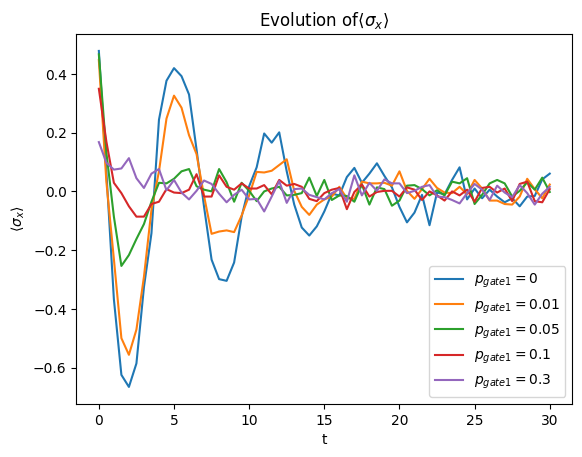

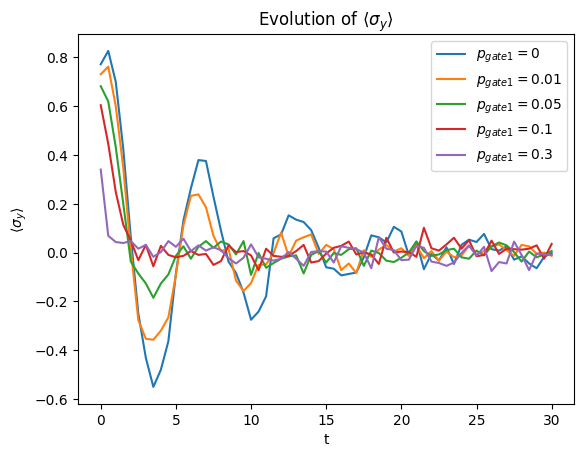

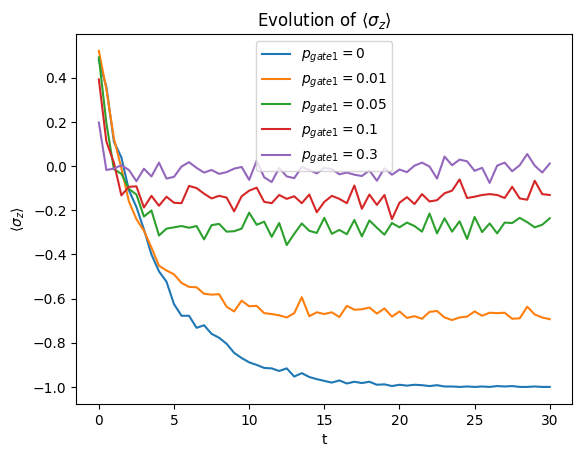

In [ ]:
time = np.arange(N+1) * delta_t

fig_x, ax_x = plt.subplots()
fig_y, ax_y = plt.subplots()
fig_z, ax_z = plt.subplots()

p_reset = 0
p_meas = 0
p_gate1 = 0

for p_gate1 in [0,0.01,0.05,0.1,0.3]:

  error_reset = pauli_error([("X", p_reset), ("I", 1 - p_reset)])
  error_meas = pauli_error([("X", p_meas), ("I", 1 - p_meas)])
  error_gate1 = pauli_error([("X", p_gate1), ("I", 1 - p_gate1)])
  error_gate2 = error_gate1.tensor(error_gate1)

  noise_bit_flip = NoiseModel()
  noise_bit_flip.add_all_qubit_quantum_error(error_reset, "reset")
  noise_bit_flip.add_all_qubit_quantum_error(error_meas, "measure")
  noise_bit_flip.add_all_qubit_quantum_error(error_gate1, ["sdg", "ry", "rz","h"])
  noise_bit_flip.add_all_qubit_quantum_error(error_gate2, ["rxx","ryy"])
  simualtor_aer = AerSimulator()
  simulator_aer_noise = AerSimulator(noise_model=noise_bit_flip)

  sx_2 = sx_2_circuit(simulator_aer_noise)
  sy_2 = sy_2_circuit(simulator_aer_noise)
  sz_2= sz_2_circuit(simulator_aer_noise)

  datos = np.column_stack((time, sx_2, sy_2, sz_2))

  np.savetxt(
    f"/content/drive/MyDrive/qiskit_noiseflipbit3_sxsysz_ns1024_pgate1_{p_gate1}.txt",
    datos,
    header="t sx sy sz",
    fmt="%.10f"
)

  ax_x.plot(time, sx_2, label=rf'$p_{{gate1}}={p_gate1}$')
  ax_y.plot(time, sy_2, label=rf'$p_{{gate1}}={p_gate1}$')
  ax_z.plot(time, sz_2, label=rf'$p_{{gate1}}={p_gate1}$')

ax_x.plot(
    t_cont, sx_cont,
    color='black', linestyle='--', linewidth=2,
    label='Continuous solution'
)

ax_y.plot(
    t_cont, sy_cont,
    color='black', linestyle='--', linewidth=2,
    label='Continuous solution'
)

ax_z.plot(
    t_cont, sz_cont,
    color='black', linestyle='--', linewidth=2,
    label='Continuous solution'
)

# Configurar figura de X
ax_x.set_xlabel('t')
ax_x.set_ylabel(r'$\langle \sigma_x \rangle$')
ax_x.set_title(r'Evolution of$\langle \sigma_x \rangle$')
ax_x.legend()

# Configurar figura de Y
ax_y.set_xlabel('t')
ax_y.set_ylabel(r'$\langle \sigma_y \rangle$')
ax_y.set_title(r'Evolution of $\langle \sigma_y \rangle$')
ax_y.legend()

# Configurar figura de Z
ax_z.set_xlabel('t')
ax_z.set_ylabel(r'$\langle \sigma_z \rangle$')
ax_z.set_title(r'Evolution of $\langle \sigma_z \rangle$')
ax_z.legend()

plt.show()


### No noise

In [ ]:
def sz_2_nonoise_circuit(simulator_aer):
  sz_2_nonoise = []
  for niter in range(0,N+1):
      qc = QuantumCircuit(2,1)
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      for i in range(0,niter):
          qc.rxx(g*delta_t,0,1)
          qc.ryy(g*delta_t,0,1)
          qc.rz(-omega*delta_t,0)
          qc.reset(1)
      qc.measure(0,0)

      job = simualtor_aer.run(qc,shots = nshots)
      results = job.result().get_counts()
      valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
      sz_2_nonoise.append(-valor)
  return sz_2_nonoise

In [ ]:
def sx_2_nonoise_circuit(simulator_aer):
  sx_2_nonoise = []
  for niter in range(0,N+1):
      qc = QuantumCircuit(2,1)
      qc.qubits
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      for i in range(0,niter):
          qc.rxx(g*delta_t,0,1)
          qc.ryy(g*delta_t,0,1)
          qc.rz(-omega*delta_t,0)
          qc.reset(1)
      qc.h(0)
      qc.measure(0,0)

      job = simulator_aer.run(qc,shots = nshots)


      results = job.result().get_counts()
      valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
      sx_2_nonoise.append(valor)
  return sx_2_nonoise

In [ ]:
def sy_2_nonoise_circuit(simulator_aer):
  sy_2_nonoise = []
  for niter in range(0,N+1):
      qc = QuantumCircuit(2,1)
      qc.qubits
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      for i in range(0,niter):
          qc.rxx(g*delta_t,0,1)
          qc.ryy(g*delta_t,0,1)
          qc.rz(-omega*delta_t,0)
          qc.reset(1)
      qc.sdg(0)
      qc.h(0)
      qc.measure(0,0)

      job = simulator_aer.run(qc,shots = nshots)

      results = job.result().get_counts()
      valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
      sy_2_nonoise.append(-valor)
  return sy_2_nonoise

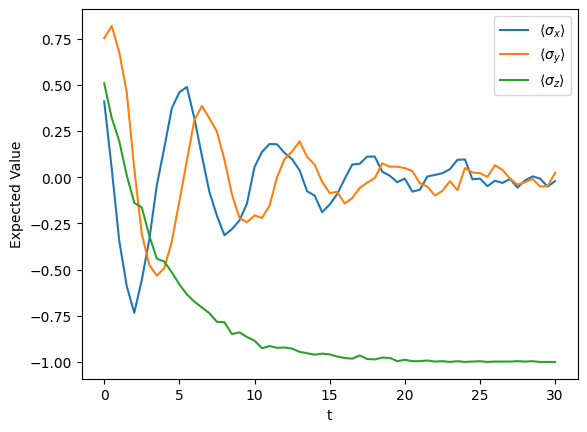

In [ ]:
simulator_aer = AerSimulator()
sx_2_nonoise = sx_2_nonoise_circuit(simulator_aer)
sy_2_nonoise= sy_2_nonoise_circuit(simulator_aer)
sz_2_nonoise= sz_2_nonoise_circuit(simulator_aer)

time = np.arange(N+1) * delta_t
plt.plot(time, sx_2_nonoise,label=rf'$\langle \sigma_x\rangle$')
plt.plot(time, sy_2_nonoise,label=rf'$\langle \sigma_y\rangle$')
plt.plot(time, sz_2_nonoise,label=rf'$\langle \sigma_z\rangle$')

plt.xlabel('t')
plt.ylabel('Expected Value')
plt.legend()


In [ ]:

datos = np.column_stack((time, sx_2, sy_2, sz_2))

np.savetxt(
    "/content/drive/MyDrive/qiskit2_nonoise_sxsysz_ns4096.txt",
    datos,
    header="t sx sy sz",
    fmt="%.10f"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
